# Hyperliquid versus Binance: lead-lag, toxic flow and a calibrated model

This notebook takes the model of [`two_venue_adverse_selection.ipynb`](two_venue_adverse_selection.ipynb) to real data.

**Data.** Public WebSocket feeds recorded from a server in Romania between 10 and 12 November 2026, about 49 hours, with the recorder of [Perpetual Alpha](https://github.com/lancellottimatteo19/perpetual-alpha):
* **Hyperliquid:** every best bid and ask update and every trade in BTC, ETH and HYPE, i.e. 1.76 million trades for 9.8 billion dollars of volume;
* **Binance USD-M futures:** the 5-level book every 100 ms for the same coins.

Every message carries the server's receive time and the exchange's own time. The raw data are not in the repository, because they amount to tens of GB and exchange feeds restrict redistribution. The repository contains the scripts, [`empirical/extract_mainnet.py`](empirical/extract_mainnet.py) and [`empirical/analyze_mainnet.py`](empirical/analyze_mainnet.py), and the aggregated results in [`empirical/results/`](empirical/results/), which this notebook reads.

The table summarises the data. Hyperliquid spreads are one tick for BTC and HYPE (0.14 bp) and half a basis point for ETH. Binance messages reach the server in about 140 ms, Hyperliquid messages in about 370 ms. Binance moves by more than 3 bp in a second in only 1–4% of seconds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace

import two_venue_sim as tv

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.float_format', '{:.2f}'.format)
RES = 'empirical/results/'
COINS = ['BTC', 'ETH', 'HYPE']

cal = pd.read_csv(RES + 'calibration.csv').set_index('coin')
cal[['hours', 'hl_spread_median_bp', 'delivery_Binance_ms_median', 'delivery_HL_ms_median',
     'total_sd_bp_1s', 'share_1s_moves_over_3bp', 'share_1s_moves_over_5bp']].rename(columns={
    'hours': 'hours of data', 'hl_spread_median_bp': 'median HL spread (bp)',
    'delivery_Binance_ms_median': 'Binance delivery (ms)', 'delivery_HL_ms_median': 'HL delivery (ms)',
    'total_sd_bp_1s': 'Binance 1 s sd (bp)', 'share_1s_moves_over_3bp': 'seconds with |move| > 3 bp',
    'share_1s_moves_over_5bp': 'seconds with |move| > 5 bp'})

,hours of data,median HL spread (bp),Binance delivery (ms),HL delivery (ms),Binance 1 s sd (bp),seconds with |move| > 3 bp,seconds with |move| > 5 bp
coin,,,,,,,
BTC,48.89,0.14,137.00,373.00,0.72,0.01,0.00
ETH,48.89,0.49,136.00,372.00,1.11,0.02,0.00
HYPE,48.89,0.14,143.00,376.00,1.31,0.04,0.01


## 1. Who leads: Binance is about half a second ahead of Hyperliquid

For each delay we correlate the Binance return over a 100 ms interval with the Hyperliquid return over the following interval. A peak to the right of zero means Binance moves first.

On the exchanges' clocks the peak is between 0.2 and 0.5 s: this is how long Hyperliquid takes to incorporate Binance's moves. On our server's clock it shifts to 0.5–0.7 s, because Hyperliquid data reach us about 230 ms after Binance data. To the left of zero the correlation is almost nil: Hyperliquid never leads Binance.

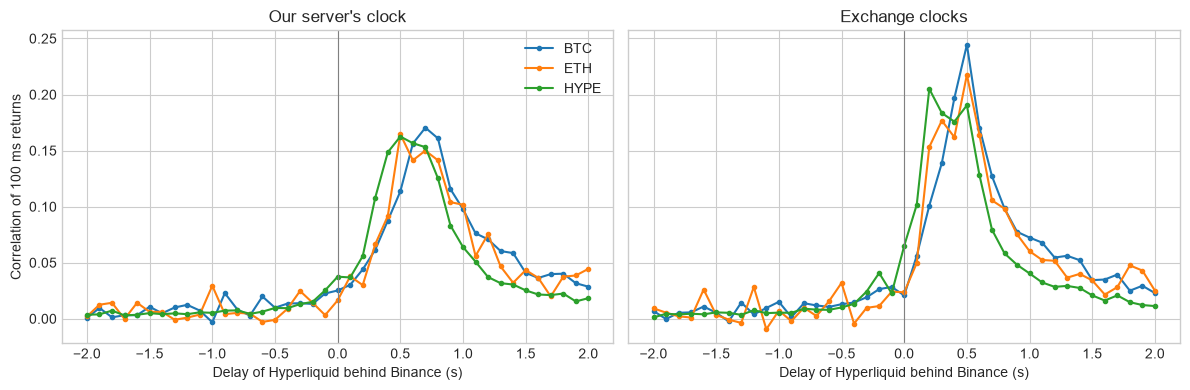

delay with the highest correlation (s)  correlation
clock    coin                                                     
exchange BTC                                     0.50         0.24
         ETH                                     0.50         0.22
         HYPE                                    0.20         0.21
receive  BTC                                     0.70         0.17
         ETH                                     0.50         0.16
         HYPE                                    0.50         0.16

In [2]:
ll = pd.read_csv(RES + 'lead_lag.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (clock, title) in zip(axes, [('receive', 'Our server\'s clock'), ('exchange', 'Exchange clocks')]):
    for coin in COINS:
        d = ll[(ll.clock == clock) & (ll.coin == coin)]
        ax.plot(d.lag_s, d['corr'], marker='o', ms=3, label=coin)
    ax.axvline(0, color='gray', lw=0.8)
    ax.set_title(title); ax.set_xlabel('Delay of Hyperliquid behind Binance (s)')
axes[0].set_ylabel('Correlation of 100 ms returns'); axes[0].legend()
plt.tight_layout(); plt.show()
ll.loc[ll.groupby(['clock', 'coin'])['corr'].idxmax(), ['clock', 'coin', 'lag_s', 'corr']].set_index(['clock', 'coin']).rename(
    columns={'lag_s': 'delay with the highest correlation (s)', 'corr': 'correlation'})

## 2. Who closes the gap between the two venues

We take the gap between the Binance mid and the Hyperliquid mid, net of the average basis over the last hour. The table shows how much of the gap each venue closes over the following seconds: the slope of the future move on the current gap.

Hyperliquid closes the gap, 24–31% of it within one second and 36–50% within five. Binance does not move. This is the simplest form of the price-discovery analysis of Hasbrouck (1995): Binance is the leading venue.

In [3]:
gap = pd.read_csv(RES + 'gap_closure.csv')
g = gap[gap.clock == 'receive'].pivot(index='horizon_s', columns='coin', values=['beta_HL', 'beta_Binance'])
g.index.name = 'horizon (s)'
g.rename(columns={'beta_HL': 'share closed by Hyperliquid', 'beta_Binance': 'share closed by Binance'}, level=0)

share closed by Hyperliquid           share closed by Binance  \
coin                                BTC  ETH HYPE                     BTC   
horizon (s)                                                                 
0.50                               0.14 0.18 0.16                    0.01   
1.00                               0.24 0.31 0.25                    0.01   
2.00                               0.34 0.43 0.31                    0.01   
5.00                               0.43 0.50 0.36                   -0.04   
10.00                              0.46 0.43 0.38                   -0.10   

                         
coin          ETH  HYPE  
horizon (s)              
0.50         0.01  0.00  
1.00         0.01 -0.01  
2.00         0.01 -0.02  
5.00        -0.06 -0.09  
10.00       -0.18 -0.19

## 3. Trades that follow Binance are costly for liquidity providers on Hyperliquid

For each Hyperliquid trade we measure:
* how far Binance had moved in the preceding second, in the taker's direction;
* the **markout** of the liquidity provider, i.e. its gain against the Hyperliquid mid 1 and 10 seconds later.

We use medians, because a few very large trades make the means unstable.

The results have the same shape for all three coins:
* with Binance **flat**, the maker earns just above zero: +0.07 bp on BTC and HYPE, +0.24 bp on ETH. This is the one-tick spread;
* when Binance has just moved **with the taker** by more than 3 bp, the maker loses between 2 and 2.8 bp over 10 seconds. This is the arbitrageurs' flow of the model;
* when the taker trades **against** Binance, the maker gains.

Trades that follow Binance are not rare: they are 33% of the volume in BTC, 47% in ETH and 57% in HYPE.

Overall, the maker's median markout at one second is 0.07–0.24 bp, far below Hyperliquid's base maker fee, which is of the order of 1.5 bp.

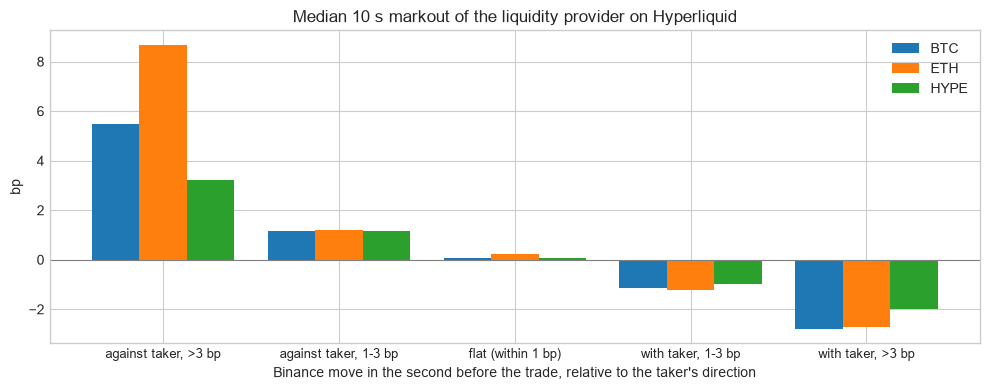

share of volume           median markout 1 s        \
coin                              BTC  ETH HYPE                BTC   ETH   
binance_before                                                             
against taker, >3 bp             0.03 0.07 0.04               2.89  3.25   
against taker, 1-3 bp            0.07 0.08 0.08               0.76  0.75   
flat (within 1 bp)               0.57 0.38 0.31               0.07  0.24   
with taker, 1-3 bp               0.21 0.25 0.22              -0.74 -0.73   
with taker, >3 bp                0.12 0.22 0.35              -1.83 -2.64   

                            median markout 10 s              
coin                   HYPE                 BTC   ETH  HYPE  
binance_before                                               
against taker, >3 bp   2.50                5.49  8.68  3.22  
against taker, 1-3 bp  0.84                1.16  1.21  1.18  
flat (within 1 bp)     0.07                0.07  0.24  0.07  
with taker, 1-3 bp    -0.49               -1.15 -1.21 -1.00  
with taker, >3 bp     -1.33               -2.80 -2.73 -2.01

In [4]:
tox = pd.read_csv(RES + 'toxicity.csv')
order = ['against taker, >3 bp', 'against taker, 1-3 bp', 'flat (within 1 bp)', 'with taker, 1-3 bp', 'with taker, >3 bp']
fig, ax = plt.subplots(figsize=(10, 4))
width = 0.27
for k, coin in enumerate(COINS):
    d = tox[tox.coin == coin].set_index('binance_before').loc[order]
    ax.bar(np.arange(len(order)) + (k - 1) * width, d['median_10s'], width, label=coin)
ax.axhline(0, color='gray', lw=0.8)
ax.set_xticks(range(len(order)), order, fontsize=9)
ax.set_xlabel('Binance move in the second before the trade, relative to the taker\'s direction')
ax.set_ylabel('bp'); ax.set_title('Median 10 s markout of the liquidity provider on Hyperliquid'); ax.legend()
plt.tight_layout(); plt.show()
t = tox.pivot(index='binance_before', columns='coin', values=['volume_share', 'median_1s', 'median_10s']).loc[order]
t.rename(columns={'volume_share': 'share of volume', 'median_1s': 'median markout 1 s', 'median_10s': 'median markout 10 s'}, level=0)

In [5]:
mk = pd.read_csv(RES + 'maker_markout.csv').set_index('coin')
mk[['trades', 'volume_usd', 'median_1s', 'volume_weighted_1s', 'volume_weighted_10s']].rename(columns={
    'volume_usd': 'volume (USD)', 'median_1s': 'median markout 1 s',
    'volume_weighted_1s': 'volume-weighted markout 1 s', 'volume_weighted_10s': 'volume-weighted markout 10 s'}).style.format(
    {'trades': '{:,.0f}', 'volume (USD)': '{:,.0f}', 'median markout 1 s': '{:.2f}',
     'volume-weighted markout 1 s': '{:.2f}', 'volume-weighted markout 10 s': '{:.2f}'})

,trades,volume (USD),median markout 1 s,volume-weighted markout 1 s,volume-weighted markout 10 s
coin,,,,,
BTC,"756,946","6,669,717,691",0.07,0.10,0.07
ETH,"368,858","2,323,646,563",0.24,0.49,1.90
HYPE,"631,800","782,773,528",0.07,0.30,-0.25


## 4. The calibrated model

The parameters of the model's efficient price are estimated from one-second Binance returns:
* the **diffusion** is the standard deviation of the returns after excluding those beyond 4 standard deviations;
* the **information events** are the excluded returns: their frequency gives the event rate, their variance (net of the diffusion) the event size.

Binance is assumed to incorporate an event within one second.

For the other parameters:
* the noise traders' **spread** is set so that the Avellaneda-Stoikov half-spread at the end of the horizon equals the one observed on Hyperliquid;
* the **arbitrageurs' cost** is set to 1 bp, consistent with the toxic flow appearing in the data after Binance moves of only 1–3 bp.

One parameter cannot be estimated from public data: the intensity of noise traders on our own quotes, kept at 0.5 fills per second per side. It sets how many noise traders trade with us relative to the arbitrageurs, so the level of the PnL depends on this choice.

In [6]:
def calibrated_market(coin, arb_cost_bp=1.0):
    c = cal.loc[coin]
    return tv.Market(sigma=c.sigma_bp_sqrt_s * tv.BP, event_rate=c.event_rate_per_s, event_sd=c.event_sd_bp * tv.BP,
                     event_duration=1.0, noise_A=0.5, noise_k=1 / (c.hl_spread_median_bp / 2 * tv.BP),
                     arb_cost=arb_cost_bp * tv.BP)

params = pd.DataFrame({coin: {'diffusion (bp/s^0.5)': cal.loc[coin, 'sigma_bp_sqrt_s'],
                              'events per minute': 60 * cal.loc[coin, 'event_rate_per_s'],
                              'event size (bp)': cal.loc[coin, 'event_sd_bp'],
                              'initial Avellaneda-Stoikov half-spread (bp)':
                                  tv.as_half_spread(calibrated_market(coin), tv.MarketMaker(), 1800) / tv.BP}
                       for coin in COINS})
params

,BTC,ETH,HYPE
diffusion (bp/s^0.5),0.42,0.69,1.01
events per minute,2.17,1.37,1.07
event size (bp),3.09,5.80,6.32
initial Avellaneda-Stoikov half-spread (bp),0.30,0.80,0.85


### The model reproduces the observed markouts

For BTC we compare like with like: the model's uninformed flow (noise traders, with no delay) with trades when Binance is flat, and the informed flow (arbitrageurs, with a 0.5 s delay) with trades after a Binance move above 3 bp. The model gives +0.07 and −3.0 bp, the data +0.07 and −2.8 bp. None of these markouts was used to estimate the parameters: this is a check outside the calibration.

In [7]:
N_PATHS = 200
mm = tv.MarketMaker(gamma=0.05)
market = calibrated_market('BTC')
price = tv.efficient_price(market, N_PATHS, np.random.default_rng(2026))

def run(mk=market, m=mm, p=None):
    return tv.simulate(mk, m, n_paths=N_PATHS, seed=7, price=price if p is None else p)

fast, slow = run(m=replace(mm, latency=0.0)), run(m=replace(mm, latency=0.5))
d = tox[tox.coin == 'BTC'].set_index('binance_before')
pd.DataFrame({
    'model (BTC)': [tv.markout_bp(fast, 'noise', 10.0), tv.markout_bp(slow, 'arbitrage', 10.0)],
    'data (BTC, median markout)': [d.loc['flat (within 1 bp)', 'median_10s'], d.loc['with taker, >3 bp', 'median_10s']],
}, index=['uninformed flow: noise traders with no delay / trades with Binance flat',
          'informed flow: arbitrageurs with a 0.5 s delay / trades after a Binance move >3 bp']
).rename_axis('10 s markout (bp)')

,model (BTC),"data (BTC, median markout)"
10 s markout (bp),,
uninformed flow: noise traders with no delay / trades with Binance flat,0.07,0.07
informed flow: arbitrageurs with a 0.5 s delay / trades after a Binance move >3 bp,-3.02,-2.80


### How much delay a market maker can afford

With one-tick spreads the margin is minimal, and the delay has a sharp threshold. In BTC the market maker earns with a delay of 0 or 100 ms behind Binance, but already loses at 200 ms. In HYPE, which is more volatile, it already loses at 100 ms.

From our server in Romania, Binance data arrive in about 140 ms, plus the time needed to send and cancel orders on Hyperliquid. A market maker running from there would therefore be beyond the threshold. This, too, is consistent with the competition.

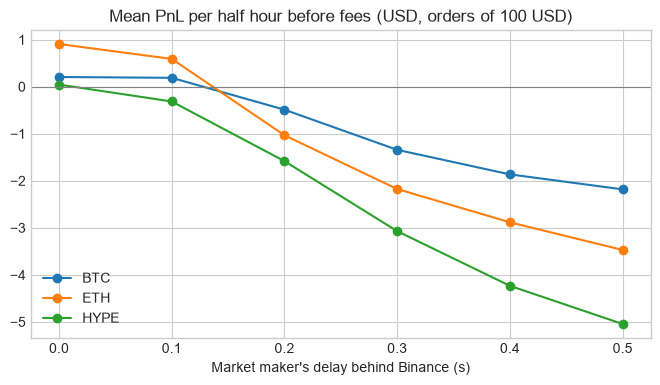

,BTC,ETH,HYPE
delay (s),,,
0.00,0.21,0.91,0.04
0.10,0.19,0.59,-0.32
0.20,-0.49,-1.03,-1.58
0.30,-1.34,-2.18,-3.07
0.40,-1.87,-2.88,-4.23
0.50,-2.18,-3.47,-5.05


In [8]:
latencies = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
curves = {}
for coin in COINS:
    mk_c = calibrated_market(coin)
    p_c = tv.efficient_price(mk_c, N_PATHS, np.random.default_rng(2026))
    curves[coin] = [run(mk=mk_c, m=replace(mm, latency=L), p=p_c)['pnl'].mean() for L in latencies]
lat = pd.DataFrame(curves, index=pd.Index(latencies, name='delay (s)'))
ax = lat.plot(marker='o', figsize=(8, 4))
ax.axhline(0, color='gray', lw=0.8)
ax.set_title('Mean PnL per half hour before fees (USD, orders of 100 USD)')
ax.set_xlabel('Market maker\'s delay behind Binance (s)')
plt.show()
lat

### Fees decide the outcome

The PnL above is before fees. With a 100 ms delay:
* at the base fee, around 1.5 bp, the market maker loses 3.8 USD per half hour;
* at zero fee it earns 0.19 USD;
* with a 0.2 bp rebate it earns 0.72 USD.

With a 300 ms delay it loses even with the rebate. The spread captured is worth tenths of a basis point: a market maker's profit on these venues depends almost entirely on latency and on its fee tier, which in turn improves with volume.

In [9]:
fees = [1.5, 1.0, 0.5, 0.0, -0.2]
tab = pd.DataFrame({f'{L:g} s delay': [run(m=replace(mm, latency=L, fee_bp=f))['pnl'].mean() for f in fees]
                    for L in [0.1, 0.3]}, index=pd.Index(fees, name='maker fee (bp)'))
tab

,0.1 s delay,0.3 s delay
maker fee (bp),,
1.50,-3.82,-7.71
1.00,-2.48,-5.59
0.50,-1.15,-3.47
0.00,0.19,-1.34
-0.20,0.72,-0.49


## Conclusions

1. **Binance leads and Hyperliquid follows,** by 0.2–0.5 s on the exchanges' clocks and 0.5–0.7 s on our server's clock.
2. **The flow that follows Binance is toxic** and makes up a third of the volume or more. Liquidity providers on Hyperliquid lose 2–3 bp on those trades and earn less than a quarter of a basis point on the others.
3. **The two-venue model, calibrated on Binance, reproduces these markouts** without being fitted to them.
4. **For a market maker on these venues, latency and fees matter, not the spread formula:** it needs less than 100–200 ms of delay behind Binance and fees close to zero. This is why market making in the most liquid crypto markets is dominated by specialised firms with dedicated infrastructure.

**Limitations.**
* Two days of a single market regime.
* The noise-trader intensity is not estimated, and the model ignores the queue, which with one-tick spreads decides who gets filled.
* The exchanges' clocks depend on the synchronisation of their servers.
* The taker side matches the trade price in 76–90% of trades.

**Next steps.**
* A month of data, covering different regimes.
* A third venue (Bybit or OKX), to estimate each venue's information share.
* A recording from a server close to the exchanges, to separate network delay from market delay.
* A study of individual addresses on Hyperliquid, where every trade is public together with the two accounts involved, to identify who the informed flow is.